# Metro Interstate Traffic Volume EDA
This notebook focuses on the exploratory data analysys of the interstate highway trafic data. From [Data Set](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume). It contains hourly Minneapolis-St Paul, MN traffic volume for westbound I-94. It includes weather and holiday features from 2012-2018. The exact location of data colaction can be seen on picture below.


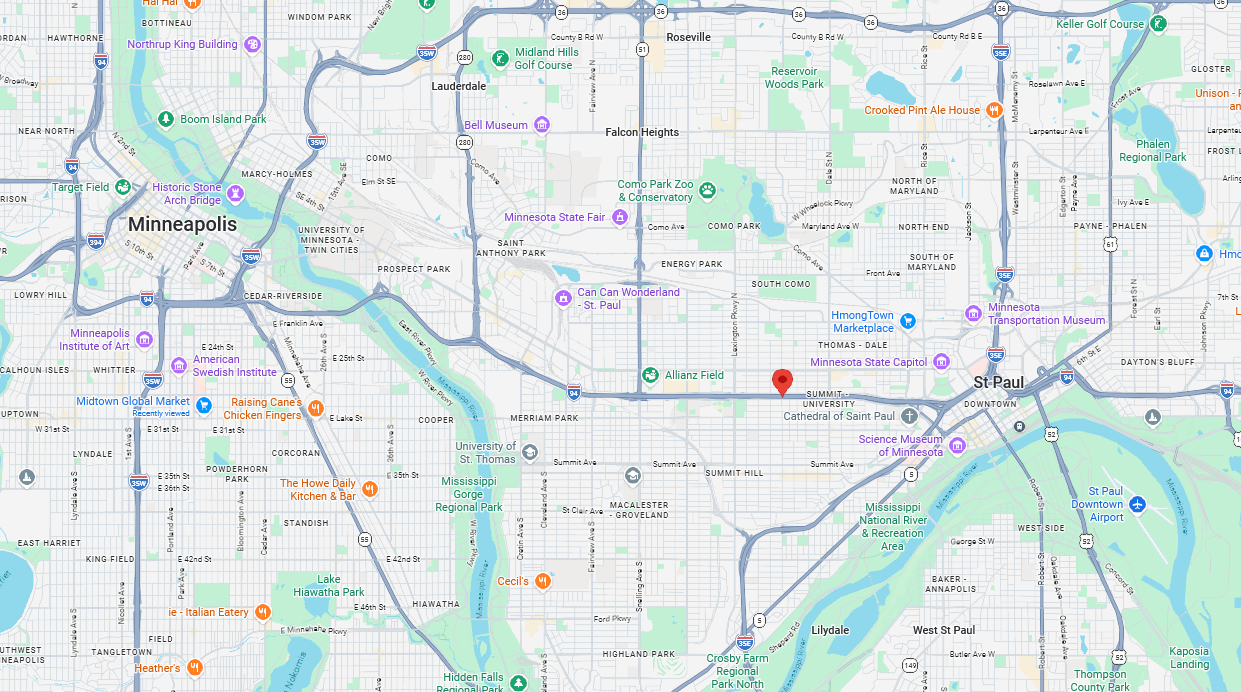

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

traficData = pd.read_csv("/content/Metro_Interstate_Traffic_Volume.csv")
traficData["temp_celc"] = traficData["temp"] - 273.15
traficData.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,temp_celc
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,15.13
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,16.21
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,16.43
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,16.98
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,17.99


## Column Description

| Column Name | Description |
| :--- | :--- |
| **holiday** | Categorical indicator of US national holidays or regional holidays (e.g., Thanksgiving, Christmas) or None/NaN for normal days. |
| **temp** | Average temperature in Kelvin. |
| **temp_celc** | Calculated temperature in Celsius (derived from `temp - 273.0`). |
| **rain_1h** | Amount in mm of rain that occurred in the hour. |
| **snow_1h** | Amount in mm of snow that occurred in the hour. |
| **clouds_all** | Percentage of cloud cover. |
| **weather_main** | Short textual description of the current weather (e.g., Rain, Snow, Clouds, Clear). |
| **weather_description** | Longer, more detailed description of the weather (e.g., light rain, heavy intensity rain). |
| **date_time** | Hour of the data collected in local CST time. |
| **traffic_volume** | Hourly I-94 westbound traffic volume (target variable). |


In [69]:
traficData.dtypes

,0
holiday,object
temp,float64
rain_1h,float64
snow_1h,float64
clouds_all,int64
weather_main,object
weather_description,object
date_time,object
traffic_volume,int64
temp_celc,float64


## Data Categorization
### 1. Numerical Variables
These represent measurable quantities:
* **Continuous**:
  * `temp` (`temp_celc`): Temperature measurements.
  * `rain_1h`: Numeric volume of rainfall.
  * `snow_1h`: Numeric volume of snowfall.
* **Discrete**:
  * `clouds_all`: Cloudiness percentage (0-100%).
  * `traffic_volume`: Count of vehicles.

### 2. Categorical Variables
These represent categories or groups:
* **Nominal**:
  * `holiday`: Categorical indicator of specific holidays (or non-holiday).
  * `weather_main`: Broad weather categories.
  * `weather_description`: Detailed weather subclassifications.
* **Datetime**:
  * `date_time`: It contains timestamp values, from which we can extract categorical features (e.g., hour of day, day of week, month).

In [70]:
for col in ['holiday', 'weather_main']:
    counts = traficData[col].value_counts()
    pcts = traficData[col].value_counts(normalize=True) * 100
    summary_df = pd.DataFrame({'Counts': counts, 'Percentage': pcts.round(2)})
    display(summary_df)

,Counts,Percentage
holiday,,
Labor Day,7,11.48
Christmas Day,6,9.84
Thanksgiving Day,6,9.84
Martin Luther King Jr Day,6,9.84
New Years Day,6,9.84
Veterans Day,5,8.20
Columbus Day,5,8.20
Memorial Day,5,8.20
Washingtons Birthday,5,8.20


,Counts,Percentage
weather_main,,
Clouds,15164,31.46
Clear,13391,27.78
Mist,5950,12.34
Rain,5672,11.77
Snow,2876,5.97
Drizzle,1821,3.78
Haze,1360,2.82
Thunderstorm,1034,2.15
Fog,912,1.89


### Observations on Holiday and Weather Distributions

**Holiday Variable:**
  - Majority of the hourly data is recorded on normal, non-holiday days.
  - Specific holidays appear in very small proportions dataset is heavily skewed towards standard weekdays/weekends.
  - As our dataset should contain hourly datapoins from 2012-2018, the holiday count is suspiciously low (one day holida should corespond to 24 entries).

**Weather Main Variable:**
  - **Clouds** and **Clear** weather dominate the dataset, accounting for nearly **59.2%** of all observation.
  - **Mist** and **Rain** are also quite common, each representing about **12%** of the hourly records.
  - Extreme or highly disruptive weather conditions like **Squalls**, **Smoke**, and **Thunderstorms** are rare occurrences.

In [71]:
display(traficData[traficData["holiday"] == "Thanksgiving Day"])

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,temp_celc
1370,Thanksgiving Day,278.54,0.0,0.0,20,Mist,mist,2012-11-22 00:00:00,919,5.39
10181,Thanksgiving Day,268.24,0.0,0.0,64,Clouds,broken clouds,2013-11-28 00:00:00,929,-4.91
19675,Thanksgiving Day,277.22,0.0,0.0,90,Mist,mist,2015-11-26 00:00:00,833,4.07
19676,Thanksgiving Day,277.22,0.0,0.0,90,Haze,haze,2015-11-26 00:00:00,833,4.07
28399,Thanksgiving Day,274.34,0.0,0.0,75,Mist,mist,2016-11-24 00:00:00,763,1.19
39180,Thanksgiving Day,271.94,0.0,0.0,1,Clear,sky is clear,2017-11-23 00:00:00,1324,-1.21


### Holiday data problem

Taking `Thanksgiving Day` as an example we can easily see that holiday marker is only applied at `00:00:00 (hh:mm:ss)` for a given date and not every hourly data point for that day. Also we can see the 2014 record is missing and we have two records for 2015's thanksgiving day. This show us that we have missing values and duplicates in our data set.

## Extracting Date and Time Features

To perform detailed analysis, we need to convert the `date_time` column to `datetime` format. This will allow us to easily extract:
- **Date** (YYYY-MM-DD)
- **Year**
- **Month**
- **Hour**
- **Day of Week** (to distinguish weekdays and weekends)

In [72]:
traficData['date_time'] = pd.to_datetime(traficData['date_time'])

traficData['date'] = traficData['date_time'].dt.date
traficData['year'] = traficData['date_time'].dt.year
traficData['month'] = traficData['date_time'].dt.month
traficData['hour'] = traficData['date_time'].dt.hour
traficData['day_of_week'] = traficData['date_time'].dt.day_name()

display(traficData[['date_time', 'date', 'year', 'month', 'hour', 'day_of_week']].head())

,date_time,date,year,month,hour,day_of_week
0,2012-10-02 09:00:00,2012-10-02,2012,10,9,Tuesday
1,2012-10-02 10:00:00,2012-10-02,2012,10,10,Tuesday
2,2012-10-02 11:00:00,2012-10-02,2012,10,11,Tuesday
3,2012-10-02 12:00:00,2012-10-02,2012,10,12,Tuesday
4,2012-10-02 13:00:00,2012-10-02,2012,10,13,Tuesday


## Fixing the holiday Data Problem

As observed earlier, holidays are only labeled at the `00:00:00` hour of the holiday date. To fix this, we can extract all dates that have a holiday designated, create a mapping from dates to holiday names, and map this back to all hours of those dates.

In [73]:
holiday_dates = traficData[traficData['holiday'].notna() & (traficData['holiday'] != 'None')]
holiday_mapping = dict(zip(holiday_dates['date'], holiday_dates['holiday']))

# Map existing holidays
traficData['holiday'] = traficData['date'].map(holiday_mapping)

# For the remaining NaN/None days, classify them as Weekday or Weekend. Used in later analysis
is_weekend = traficData['day_of_week'].isin(['Saturday', 'Sunday'])
traficData['holiday'] = traficData['holiday'].fillna(is_weekend.map({True: 'Weekend', False: 'Weekday'}))

display(traficData.loc[traficData["holiday"] == "Thanksgiving Day", ["date_time", "holiday"]].head(7))

,date_time,holiday
1370,2012-11-22 00:00:00,Thanksgiving Day
1371,2012-11-22 01:00:00,Thanksgiving Day
1372,2012-11-22 02:00:00,Thanksgiving Day
1373,2012-11-22 03:00:00,Thanksgiving Day
1374,2012-11-22 04:00:00,Thanksgiving Day
1375,2012-11-22 05:00:00,Thanksgiving Day
1376,2012-11-22 06:00:00,Thanksgiving Day


## Numerical summary

In [74]:
display(traficData[["temp_celc", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]].describe())


,temp_celc,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,8.055870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,-273.150000,0.000000,0.000000,0.000000,0.000000
25%,-0.990000,0.000000,0.000000,1.000000,1193.000000
50%,9.300000,0.000000,0.000000,64.000000,3380.000000
75%,18.656000,0.000000,0.000000,90.000000,4933.000000
max,36.920000,9831.300000,0.510000,100.000000,7280.000000


Numerical summary on relevant data can give us general idea on data ranges for our dataset, as weather could vary a lot depending on climate. For our dataset only *~25%* of hour's were below 0, we could see that most of the time there is no rainfall and no snow fall as even 3rd quartile is still 0 for them.

It also could show us flawed data points. -273 deg Celcius is unrealistic as 9m of rainfall.

In [75]:
print("Temperture anomaly")
display(traficData.loc[traficData["temp_celc"] < -30, ["date_time", "temp_celc"]])

print("Rain anomaly")
display(traficData.loc[traficData["rain_1h"] > 100, ["date_time", "rain_1h"]])

Temperture anomaly


,date_time,temp_celc
11898,2014-01-31 03:00:00,-273.15
11899,2014-01-31 04:00:00,-273.15
11900,2014-01-31 05:00:00,-273.15
11901,2014-01-31 06:00:00,-273.15
11946,2014-02-02 03:00:00,-273.15
11947,2014-02-02 04:00:00,-273.15
11948,2014-02-02 05:00:00,-273.15
11949,2014-02-02 06:00:00,-273.15
11950,2014-02-02 07:00:00,-273.15
11951,2014-02-02 08:00:00,-273.15


Rain anomaly


,date_time,rain_1h
24872,2016-07-11 17:00:00,9831.3


For the temperature we can cleary see that at 31 Jan 14 3:00-6:00  and 2 Feb 14 3:00-8:00 the temperature data was missing and the Kelvin value was set to 0.

## Trafic data distribiution

In [76]:
# @title Color Palette
colorPalette = {
    "red": {
        80: "#750e13",
        70: "#a2191f",
        60: "#da1e28",
        50: "#fa4d56",
        40: "#ff8389",
        30: "#ffb3b8",
        20: "#ffd7d9",
        10: "#fff1f1"
    },
    "purple": {
        80: "#491d8b",
        70: "#6929c4",
        60: "#8a3ffc",
        50: "#a56eff",
        40: "#be95ff",
        30: "#d4bbff",
        20: "#e8daff",
        10: "#f6f2ff"
    },
    "cyan": {
        80: "#003a6d",
        70: "#00539a",
        60: "#0072c3",
        50: "#1192e8",
        40: "#33b1ff",
        30: "#82cfff",
        20: "#bae6ff",
        10: "#e5f6ff"
    },
    "teal": {
        80: "#004144",
        70: "#005d5d",
        60: "#007d79",
        50: "#009d9a",
        40: "#08bdba",
        30: "#3ddbd9",
        20: "#9ef0f0",
        10: "#d9fbfb"
    }
}
tempMap = matplotlib.colors.LinearSegmentedColormap.from_list("", list(colorPalette["cyan"].values()) + list(colorPalette["red"].values())[::-1])
redMap = matplotlib.colors.LinearSegmentedColormap.from_list("", list(colorPalette["red"].values())[::-1])
cyanMap = matplotlib.colors.LinearSegmentedColormap.from_list("", list(colorPalette["cyan"].values()))

purpleMap = matplotlib.colors.LinearSegmentedColormap.from_list("", list(colorPalette["purple"].values())[::-1])
tealMap = matplotlib.colors.LinearSegmentedColormap.from_list("", list(colorPalette["teal"].values())[::-1])

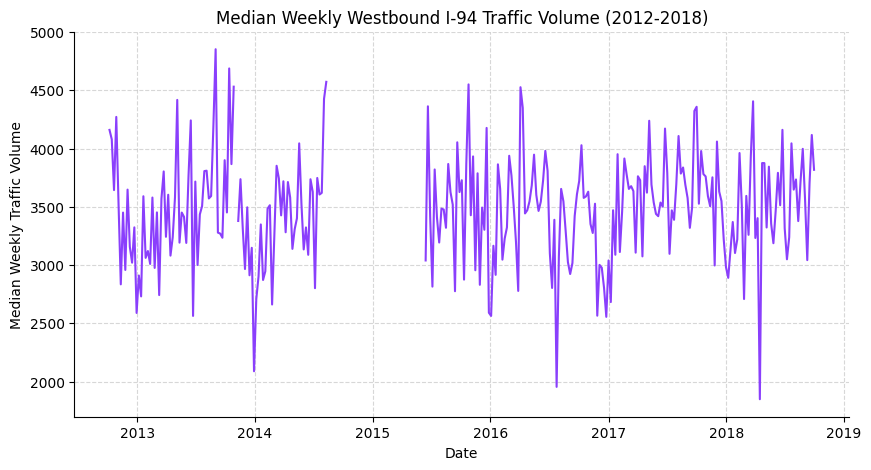

In [77]:
temp_df = traficData.set_index('date_time')
weekly_traffic = temp_df['traffic_volume'].resample('W').median().reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(weekly_traffic["date_time"], weekly_traffic["traffic_volume"], color=colorPalette["purple"][60], linewidth=1.5)

ax.set_xlabel("Date")
ax.set_ylabel("Median Weekly Traffic Volume")
ax.set_title("Median Weekly Westbound I-94 Traffic Volume (2012-2018)")

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

### Investigating Missing Data

Looking at our weekly trend visualization I did not found any meaningfull change over the years but there is a clear visual gap around 2014 and 2015, there is also small one in 2013. This chart showed us that we have missing data and not all trafic readings are present.

In [78]:
traficDataSorted = traficData.sort_values('date_time')
traficDataSorted['time_diff'] = traficDataSorted['date_time'].diff()

largeGaps = traficDataSorted[traficDataSorted['time_diff'] > pd.Timedelta(days=1)]
display(largeGaps[["date_time", "time_diff"]])

,date_time,time_diff
3220,2013-01-30 01:00:00,1 days 01:00:00
8741,2013-09-01 23:00:00,1 days 23:00:00
8768,2013-09-04 08:00:00,1 days 06:00:00
9661,2013-11-06 04:00:00,10 days 03:00:00
14012,2014-05-04 05:00:00,4 days 21:00:00
15797,2014-07-30 09:00:00,2 days 17:00:00
15865,2014-08-03 11:00:00,1 days 09:00:00
15971,2015-06-11 20:00:00,307 days 19:00:00
15978,2015-06-19 18:00:00,4 days 22:00:00
15980,2015-06-22 00:00:00,1 days 06:00:00


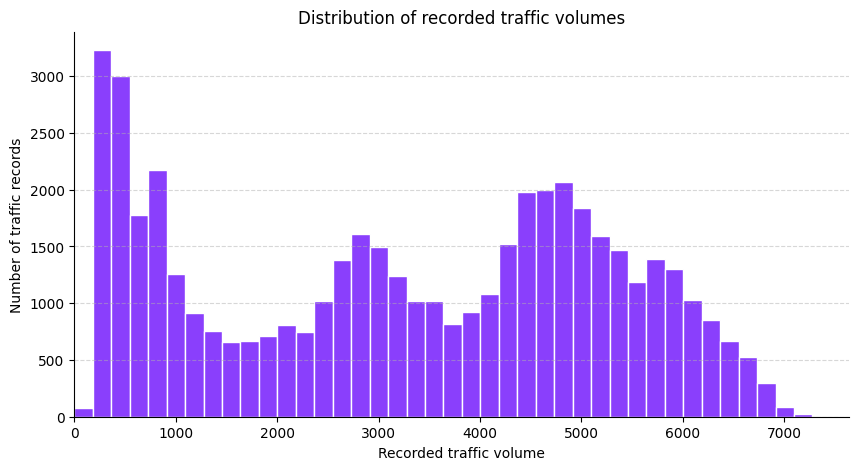

In [79]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(traficData["traffic_volume"], bins=40, color=colorPalette["purple"][60], edgecolor="white")

ax.set_xlabel("Recorded traffic volume")
ax.set_ylabel("Number of traffic records")
ax.set_title("Distribution of recorded traffic volumes")

ax.ticklabel_format(style="plain", axis="x")
ax.set_xlim(0)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
plt.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.show()

## Traffic Volume Distribution

Traffic volume histogram shows several distinct characteristics of westbound I-94 traffic behavior:

1. **Multimodal Distribution:** There are three peaks in the data:
   - **Low-Volume Peak (0 - 1,000)** This peak shows periods with minimal traffic, which probably represent overnight hours.
   - **Mid-Volume Peek (2,500 - 3,500)** This peak probably represents mid-day traffic volume on non rush-hours and after them.
   - **High-Volume Peak (4,500 - 5,500):** This represents regular daytime traffic during rush-hours.

3. **Capacity Limit:** The distribution drops off above 6,500 vehicles per hour. It represents the throughput limitation of the highway.

## Traffic Volume by Hour of Day

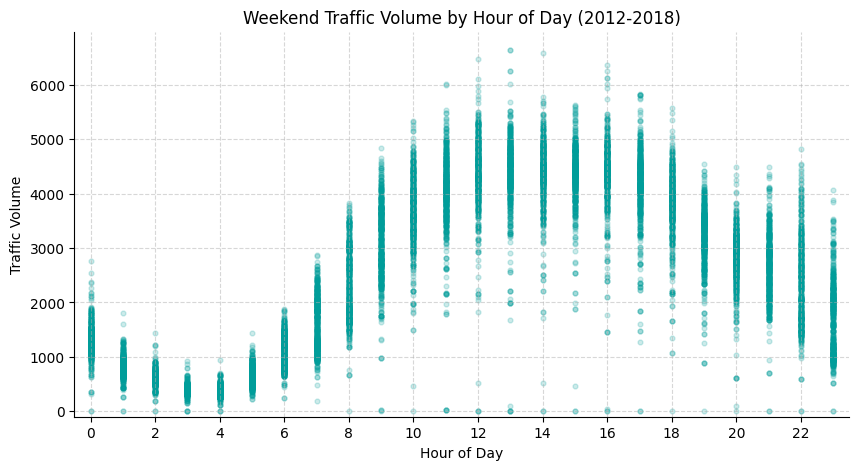

In [80]:
weekendMask = traficData["holiday"] == "Weekend"
weekendTraffic = traficData.loc[weekendMask, ["hour", "traffic_volume"]].copy()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(weekendTraffic["hour"], weekendTraffic["traffic_volume"], color=colorPalette["teal"][50], s=12, alpha=0.20)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Traffic Volume")
ax.set_title("Weekend Traffic Volume by Hour of Day (2012-2018)")

ax.set_xlim(-0.5, 23.5)
ax.set_ylim(-100)
plt.xticks(np.arange(0, 24, 2.0))
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

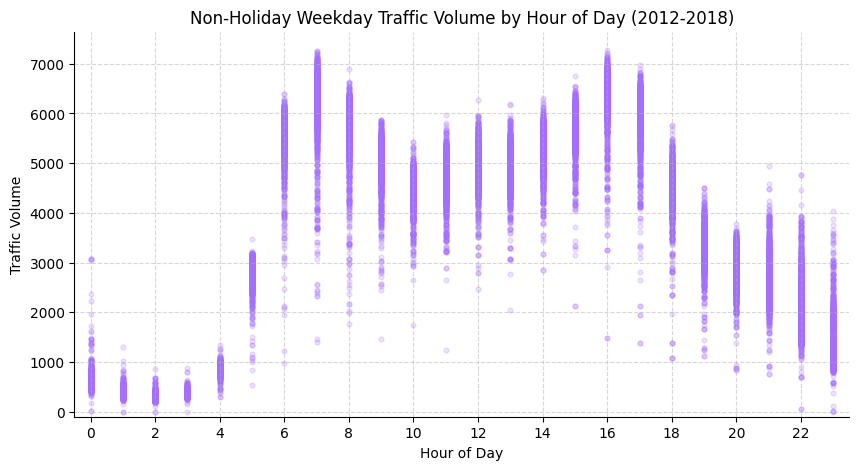

In [81]:
weekdayMask = traficData["holiday"] == "Weekday"
holidayTraffic = traficData.loc[weekdayMask, ["hour", "traffic_volume"]].copy()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(holidayTraffic["hour"], holidayTraffic["traffic_volume"], color=colorPalette["purple"][50], s=12, alpha=0.20)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Traffic Volume")
ax.set_title("Non-Holiday Weekday Traffic Volume by Hour of Day (2012-2018)")

ax.set_xlim(-0.5, 23.5)
ax.set_ylim(-100)
plt.xticks(np.arange(0, 24, 2.0))
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

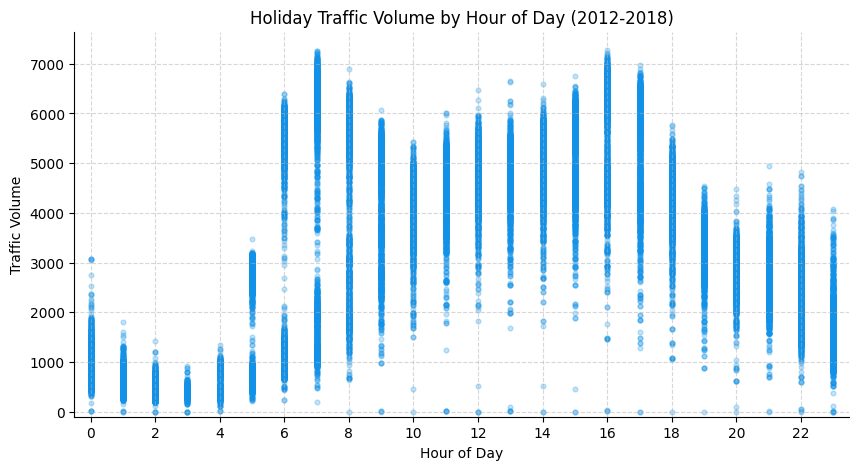

In [82]:
holidayTraffic = (traficData["holiday"] != "Weekday") & (traficData["holiday"] != "Weekend")
holidayTraffic = traficData.loc[(traficData["holiday"] != "None"), ["hour", "traffic_volume", "temp_celc", "rain_1h", "snow_1h"]].copy()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(holidayTraffic["hour"], holidayTraffic["traffic_volume"], color=colorPalette["cyan"][50], s=12, alpha=0.25)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Traffic Volume")
ax.set_title("Holiday Traffic Volume by Hour of Day (2012-2018)")

ax.set_xlim(-0.5, 23.5)
ax.set_ylim(-100)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
plt.xticks(np.arange(0, 24, 2.0))
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

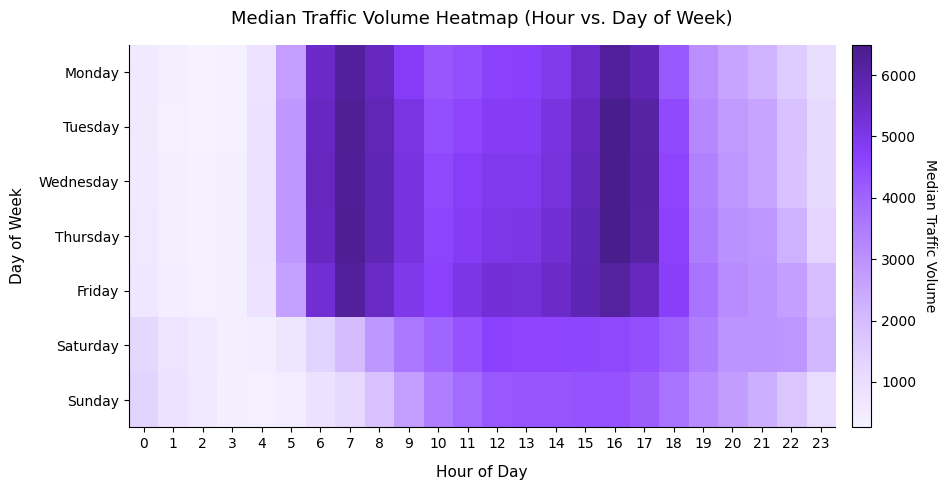

In [88]:
heatmap_data = traficData.groupby(['day_of_week', 'hour'])['traffic_volume'].median().reset_index()
heatmap_pivot = heatmap_data.pivot(index='day_of_week', columns='hour', values='traffic_volume')

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_pivot = heatmap_pivot.reindex(day_order)

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(heatmap_pivot.values, cmap=purpleMap, aspect='auto')

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('Median Traffic Volume', rotation=270, labelpad=15)

ax.set_xticks(np.arange(24))
ax.set_xticklabels(np.arange(24))
ax.set_yticks(np.arange(7))
ax.set_yticklabels(day_order)

ax.set_xlabel('Hour of Day', fontsize=11, labelpad=10)
ax.set_ylabel('Day of Week', fontsize=11, labelpad=10)
ax.set_title('Median Traffic Volume Heatmap (Hour vs. Day of Week)', fontsize=13, pad=15)

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

## Comparing Weekend, Weekday, and Holiday Traffic Patterns

Comparing these three scatter plot shows three distinct commuter patterns depending on the type of day:

1. **Non-Holiday Weekdays:**
   The non-holiday weekday plot shows a bimodal structure with surges during morning (6:00 - 8:00) and afternoon (15:00 - 17:00) rush hours. During these times, traffic volume peaks above 7,000 vehicles/hour as commuting traffic reaches maximum highway capacity.

2. **Non-Holiday Weekends:**
   The weekend plot lacks any sudden morning or evening spikes, showin a smooth bell-shaped curve instead.

3. **Holidays:**
   The holiday plot displays an hybrid pattern. This shows that not all holidays are treated as weekends and some of them are behaving like a normal weekday.

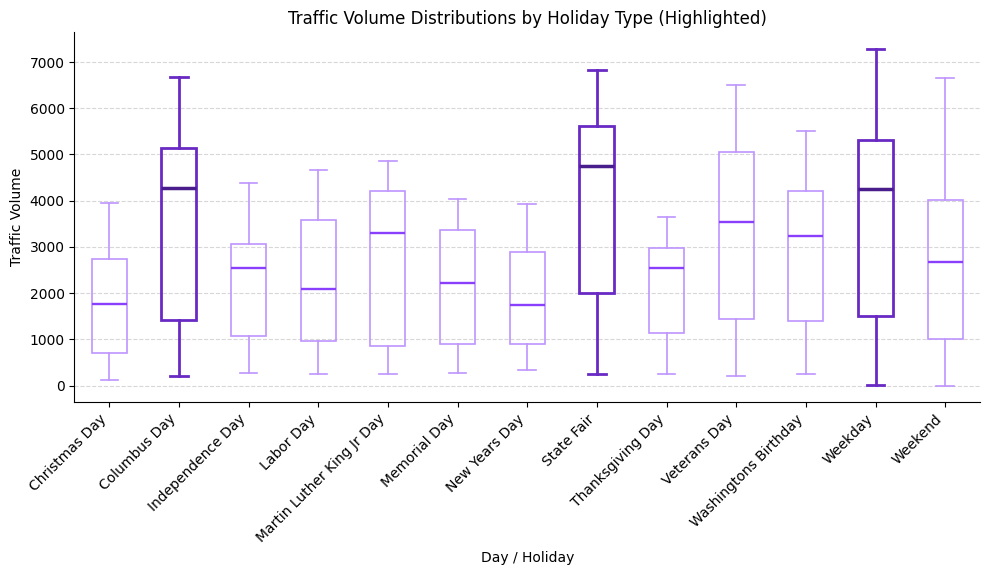

In [84]:
fig, ax = plt.subplots(figsize=(10, 6))

categories = sorted(traficData['holiday'].unique())
data_groups = [traficData[traficData['holiday'] == cat]['traffic_volume'] for cat in categories]
highlights = {'Weekday', 'State Fair', 'Columbus Day'}

c_dark, c_light = colorPalette["purple"][70], colorPalette["purple"][40]
m_dark, m_light = colorPalette["purple"][80], colorPalette["purple"][60]

bp = ax.boxplot(data_groups, tick_labels=categories, patch_artist=True, showfliers=True)

# Coloring with Holidays similar to weekday higlighted
for i, cat in enumerate(categories):
    hl = cat in highlights
    color = c_dark if hl else c_light
    med_color = m_dark if hl else m_light
    width = 2.0 if hl else 1.2

    bp['boxes'][i].set(facecolor='none', edgecolor=color, linewidth=width)
    bp['medians'][i].set(color=med_color, linewidth=width + 0.5)
    for j in range(2):
        bp['whiskers'][2*i + j].set(color=color, linewidth=width)
        bp['caps'][2*i + j].set(color=color, linewidth=width)

for flier in bp['fliers']:
    flier.set(marker='o', color=c_light, alpha=0.3, markersize=3)

# Plot styling
fig.suptitle("")
ax.set_title("Traffic Volume Distributions by Holiday Type (Highlighted)")
ax.set_xlabel("Day / Holiday")
ax.set_ylabel("Traffic Volume")
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.show()

### Traffic Volume by Holiday Type

From the highlighted boxplot above, we can draw several key conclusions about how different holidays impact traffic volume on I-94:

1. **Standard Commuting Days (Highlighted in Dark Purple):**
   - **Weekday** traffic shows a high median volume (4,200 vehicles/hour) and a wide spread, reflecting heavy regular commuting, rush hours and night stall of the traffic.
   - **State Fair** and **Columbus Day** exhibit traffic distributions that are similar to standard weekdays, with high medians and upper ranges. This confirms they behave more like normal working days and explains why the distribiution of holiday trafic looks like overlaped weekend and weekday traffic.

2. **Low-Traffic Major Holidays:**
   - **Christmas Day**, **New Year's Day**, and **Thanksgiving Day** have significantly lower traffic volume. Their medians drop below 2,000 vehicles/hour, indicating a major reduction in commuting activity.

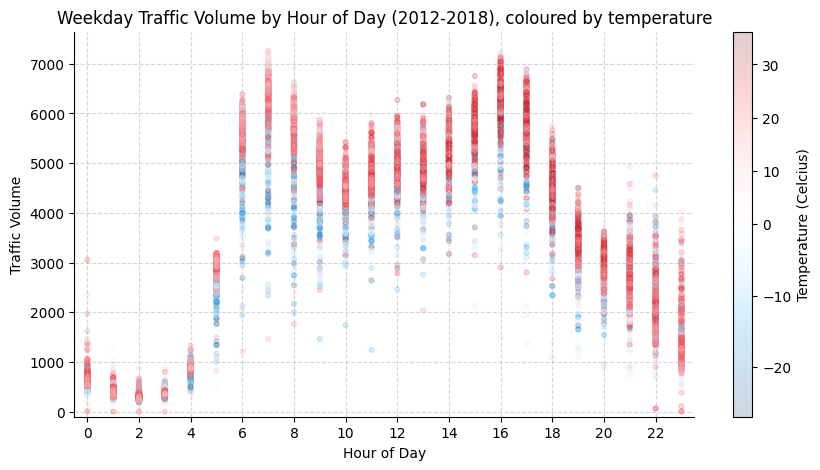

In [85]:
weekdayTrafficTemp = traficData.loc[(weekdayMask) & (traficData["temp"] != 0), ["hour", "traffic_volume", "temp_celc"]].copy()

norm = matplotlib.colors.TwoSlopeNorm(vmin=weekdayTrafficTemp["temp_celc"].min(), vcenter=0.0, vmax=weekdayTrafficTemp["temp_celc"].max())

fig, ax = plt.subplots(figsize=(10, 5))
points = ax.scatter(weekdayTrafficTemp["hour"], weekdayTrafficTemp["traffic_volume"], c=weekdayTrafficTemp["temp_celc"], cmap=tempMap, norm=norm, s=12, alpha=0.20)
fig.colorbar(points, ax=ax, label="Temperature (Celcius)")

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Traffic Volume")
ax.set_title("Weekday Traffic Volume by Hour of Day (2012-2018), coloured by temperature")

ax.set_xlim(-0.5, 23.5)
ax.set_ylim(-100)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
plt.xticks(np.arange(0, 24, 2.0))
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

### Weekday Traffic Volume Coloured by Temperature

1. **High Volume Consistency:**
   The morning (6:00 - 8:00) and afternoon (15:00 - 17:00) rush hours maintain high traffic volumes regardless of whether the temperatures are warm or freezing.

2. **Cold Temperature Spread**
   During the day we clearly can see the lower traffic volumes are mainly in temperatures below 0. This suggests that sub-zero temperatures may introduce more variability, delays, or spread in traffic volume during the commute patterns.

3. **Off-Peak Weather**
   Nighttime traffic (22:00 - 4:00) remains low regardless of the temperature, showing that low traffic is determined by human commuting cycle rather than weather variations.

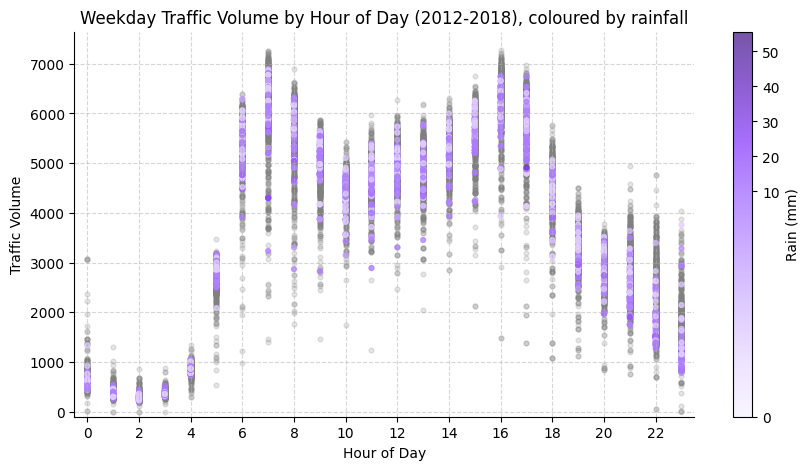

In [86]:
weekdayTrafficWithoutRainAndSnow = traficData.loc[(traficData["holiday"] == "Weekday") & (traficData["rain_1h"] < 0.01) &  (traficData["snow_1h"] < 0.01), ["hour", "traffic_volume"]].copy()
weekdayTrafficRain = traficData.loc[(traficData["holiday"] == "Weekday") & (traficData["rain_1h"] > 0.01) &  (traficData["rain_1h"] < 1000), ["hour", "traffic_volume", "rain_1h"]].copy()

rain_median = weekdayTrafficRain["rain_1h"].median()
rain_max = weekdayTrafficRain["rain_1h"].max()
rainNorm = matplotlib.colors.TwoSlopeNorm(vmin=0.0, vcenter=max(0.01, rain_median), vmax=max(0.1, rain_max))

fig, ax = plt.subplots(figsize=(10, 5))
# Other Days
ax.scatter(weekdayTrafficWithoutRainAndSnow["hour"], weekdayTrafficWithoutRainAndSnow["traffic_volume"], color="gray", s=12, alpha=0.20)
# Rainy Days
p1 = ax.scatter(weekdayTrafficRain["hour"], weekdayTrafficRain["traffic_volume"], c=weekdayTrafficRain["rain_1h"], cmap=purpleMap, norm=rainNorm, s=12, alpha=0.75)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Traffic Volume")
ax.set_title("Weekday Traffic Volume by Hour of Day (2012-2018), coloured by rainfall")

ax.set_xlim(-0.5, 23.5)
ax.set_ylim(-100)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
plt.xticks(np.arange(0, 24, 2.0))
fig.colorbar(p1, ax=ax, label="Rain (mm)")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

### Weekday Traffic Volume Coloured by Rainfall

1. **Rainfall Distribution:**
   Most commuting hours experience little to no rainfall, as represented by the dominant light purple and gray markers. Heavy rain (dark purple markers) are relatively rare occurrences.

2. **Peak Hour Resilience:**
   The rush hours still experience heavy traffic approaching maximum capacity even under heavier rainfall. This suggests that rain does not change commute patterns.

3. **Absence of Extremes:**
   There is a slight drop in the absolute maximum traffic capacity during periods of high rainfall intensity. This likely reflects natural traffic flow decrese as visibility and road conditions deteriorate becomes worse.

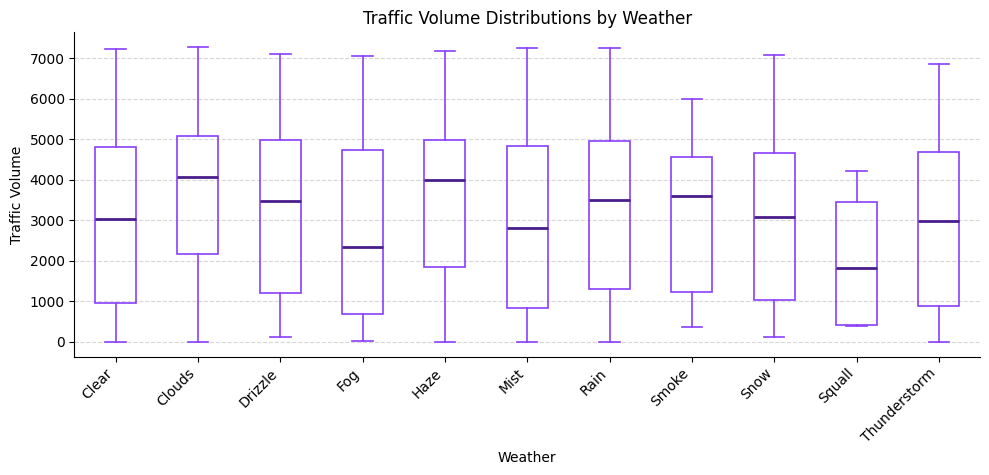

In [87]:
fig, ax = plt.subplots(figsize=(10, 5))

categories = sorted(traficData['weather_main'].unique())
data_groups = [traficData[traficData['weather_main'] == cat]['traffic_volume'] for cat in categories]

bp = ax.boxplot(data_groups, tick_labels=categories, patch_artist=True, showfliers=True)

for i, cat in enumerate(categories):
    bp['boxes'][i].set(facecolor='none', edgecolor=colorPalette["purple"][60], linewidth=1.2)
    bp['medians'][i].set(color=colorPalette["purple"][80], linewidth=2.0)
    for j in range(2):
        bp['whiskers'][2*i + j].set(color=colorPalette["purple"][60], linewidth=1.2)
        bp['caps'][2*i + j].set(color=colorPalette["purple"][60], linewidth=1.2)

# Plot styling
fig.suptitle("")
ax.set_title("Traffic Volume Distributions by Weather")
ax.set_xlabel("Weather")
ax.set_ylabel("Traffic Volume")
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.show()

### Traffic Volume Distributions by Weather
1. **High Consistency Across Most Weather Conditions:**
   The median traffic volume remains stable across most common weather types such as `Clear`, `Clouds`, `Drizzle`, `Haze`, `Rain`, and `Snow`. This indicates that drivers still travel regardless of mild-to-moderate weather disruptions.

2. **Reduced Traffic Under Extreme Conditions:**
   Extreme or highly disruptive weather conditions like `Squall` and `Fog` show a noticeable drop in median traffic volume, but it also could be the fault of rarity of those events (only 4 squall's, they can happen at night and median would be sqewed). This could suggest that severe weather events deter drivers from using the highway or reduce overall throughput.

3. **Tight Spread in Minor Categories:**
   Categories like `Squall` and `Smoke` show much tighter box ranges. However, this is heavily influenced by the sample size (events occur very infrequently).

## Other interesting ways to explore

1. **Monthly Trafic trend**
A boxplot showing traffic volume grouped by `month`. It helps determine if cold winter months overall decreases monthly average traffic due to road hazards, compared to summer vacations.

2. **Traffic Volume vs. Cloud Cover**
A scatter plot checking traffic volume against the cloudiness percentage. To investigate whether dark, overcast days (unassociated with rain/snow) influence traffic flow.

3. **Investigations with additional data**
Interesting thing to look at would be to check if there is incresed traffic before/after major events in each city, like concert or some sporting event. This would show us if people travel to each city for those types of activities.